In [13]:
import sys
from pathlib import Path

# Agrego la raíz del proyecto al path
ROOT_PROY = Path.cwd().resolve().parents[1]   # texture_eval/notebooks -> raíz
sys.path.insert(0, str(ROOT_PROY))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from common.io_utils import cargar_subset, cargar_imagen, cargar_gt
from common.generar_gt_utils import celulas_desde_gt, mapa_gt
from texture_eval.glcm_features import glcm_celula

{'cell_id': '208C67P28N_ThinF_IMG_20150819_115417_1-1', 'image_id': 'IMG_20150819_115417.jpg', 'patient_id': '208C67P28N_ThinF', 'split': 'train', 'label': 'Parasitized'}


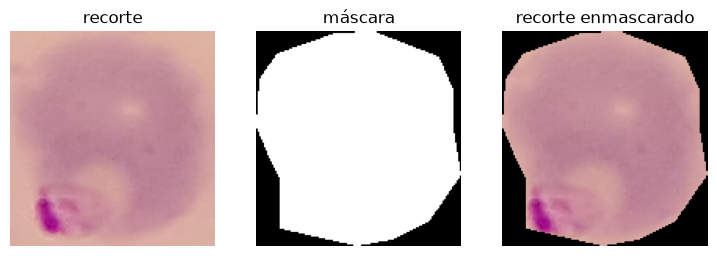

{'cell_id': '208C67P28N_ThinF_IMG_20150819_115417_1-2', 'image_id': 'IMG_20150819_115417.jpg', 'patient_id': '208C67P28N_ThinF', 'split': 'train', 'label': 'Parasitized'}


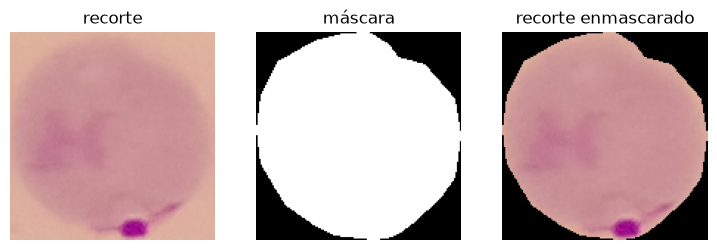

{'cell_id': '208C67P28N_ThinF_IMG_20150819_115417_1-3', 'image_id': 'IMG_20150819_115417.jpg', 'patient_id': '208C67P28N_ThinF', 'split': 'train', 'label': 'Parasitized'}


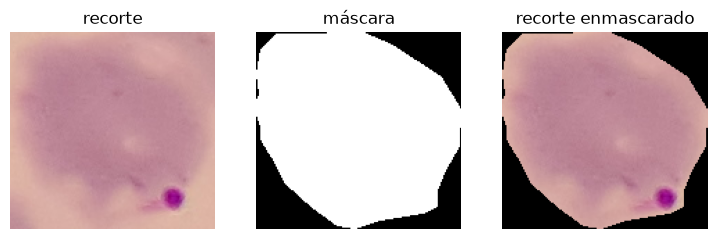

{'cell_id': '208C67P28N_ThinF_IMG_20150819_115417_1-4', 'image_id': 'IMG_20150819_115417.jpg', 'patient_id': '208C67P28N_ThinF', 'split': 'train', 'label': 'Parasitized'}


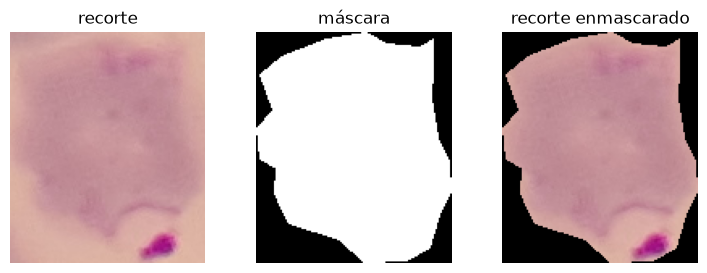

{'cell_id': '208C67P28N_ThinF_IMG_20150819_115417_1-5', 'image_id': 'IMG_20150819_115417.jpg', 'patient_id': '208C67P28N_ThinF', 'split': 'train', 'label': 'Uninfected'}


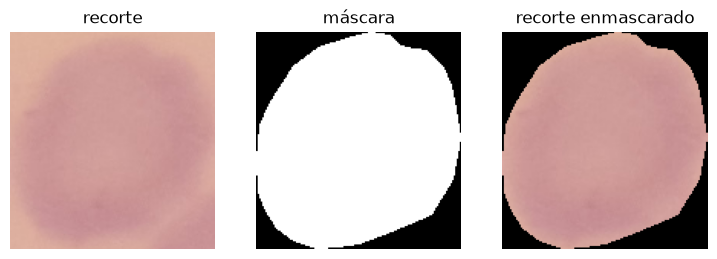

In [14]:
#grafico algunas celulas con sus mascaras y el recorte resultante
gen = celulas_desde_gt()

for i in range(5):
    
    meta, crop, mask = next(gen)
    print(meta)

    fig, axs = plt.subplots(1, 3, figsize=(9, 3))
    axs[0].imshow(crop);                       axs[0].set_title("recorte")
    axs[1].imshow(mask, cmap="gray");          axs[1].set_title("máscara")
    axs[2].imshow(crop * (mask[..., None] > 0)); axs[2].set_title("recorte enmascarado")
    for ax in axs: ax.axis("off")
    plt.show()

208C67P28N_ThinF_IMG_20150819_115417_1-1 Parasitized


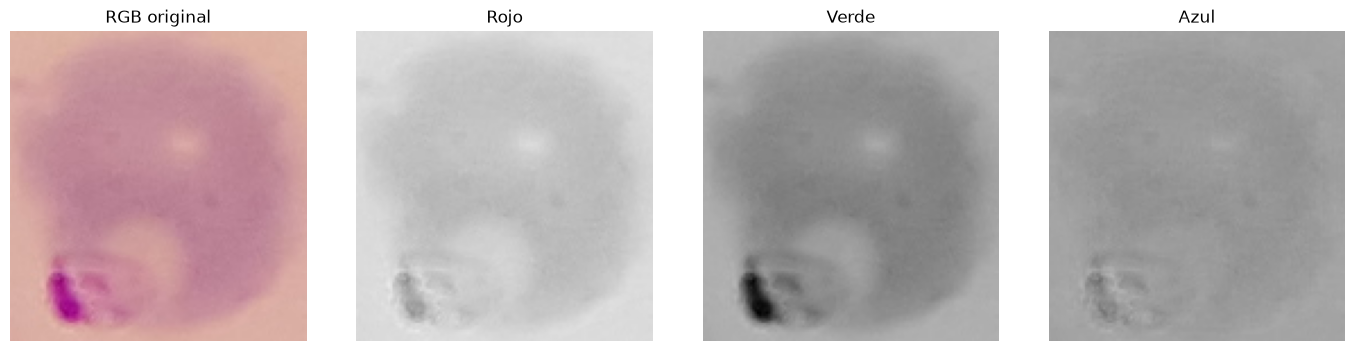

In [15]:
#Veo en qué canal hay más contraste entre parásito y cistoplasma

# Elijo una célula parasitada para ver dónde se nota más el parásito
for meta, crop, mask in celulas_desde_gt():
    if meta["label"] == "Parasitized":
        break
print(meta["cell_id"], meta["label"])

nombres = ["Rojo", "Verde", "Azul"]
fig, axs = plt.subplots(1, 4, figsize=(14, 3.5))

axs[0].imshow(crop)
axs[0].set_title("RGB original")

for i, nombre in enumerate(nombres):
    canal = crop[:, :, i]
    # vmin/vmax fijos (0-255) para que los tres canales se comparen con la misma escala
    axs[i + 1].imshow(canal, cmap="gray", vmin=0, vmax=255)
    axs[i + 1].set_title(nombre)

for ax in axs: ax.axis("off")
plt.tight_layout()
plt.show()

In [16]:
#Calculamos GLCM de todas las células
filas = []
for meta, crop, mask in celulas_desde_gt():
    feats = glcm_celula(crop, mask) #calcula parámetros de textura
    if feats is None: #salteamos invalida
        continue
    filas.append({**meta, **feats})

df = pd.DataFrame(filas)
df.groupby(["split", "label"]).size() # cantidad de células por partición y clase

split  label           
test   Parasitized           23
       Uninfected           976
       White_Blood_Cell       3
train  Parasitized          217
       Uninfected          2135
       White_Blood_Cell      10
dtype: int64

In [17]:
#Guardamos resultados
out = ROOT_PROY / "texture_eval" / "results"
out.mkdir(parents=True, exist_ok=True)
df.to_csv(out / "features_texture_gt_provisorio.csv", index=False)

In [18]:
from scipy.stats import mannwhitneyu

CLASES = ["Parasitized", "Uninfected"]
#agarro las del set de entrenamiento que no sean leucocitos
train = df[(df["split"] == "train") & (df["label"].isin(CLASES))].copy() 
# Células por paciente y clase, para ver el desbalance
print(train.groupby(["patient_id", "label"]).size().unstack(fill_value=0))

# columnas de textura (excluyo metadatos y las auxiliares de conteo)
meta_cols = ["cell_id", "image_id", "patient_id", "split", "label", "n_pixeles", "n_pares_min"]
feat_cols = [c for c in train.columns if c not in meta_cols]

label             Parasitized  Uninfected
patient_id                               
208C67P28N_ThinF           21         457
209C68P29N_ThinF          145         268
211C70P31_ThinF            37         193
212C71P32_ThinF             5         496
263C115P76ThinF             5         486
282C134P95ThinF             4         235


In [19]:
#Calculamos AUC para determinar cual feature permite clasificar mejor
#En vez de calcular el ROC variando los umbrales, calculamos el U
#de Mann-Whitney y normalizamos por todas las combinaciones de pares posibles
filas = []
for f in feat_cols:
    p = train.loc[train.label == "Parasitized", f].dropna()
    u = train.loc[train.label == "Uninfected", f].dropna()
    U, pval = mannwhitneyu(p, u, alternative="two-sided") # test de Mann-Whitney
    auc = U / (len(p) * len(u))          # P(parasitada > no infectada) = AUC (área bajo la ROC)
    filas.append({"feature": f, "auc": auc,
                  "separacion": max(auc, 1 - auc),   # 0.5 = no sirve para clasificar, 1 = clasificación perfecta
                  "sentido": "mayor en parasitadas" if auc > 0.5 else "menor en parasitadas",
                  "p_value": pval})

# Ranking de mejor a peor descriptor
ranking = (pd.DataFrame(filas)
           .sort_values("separacion", ascending=False)
           .reset_index(drop=True))
ranking

,feature,auc,separacion,sentido,p_value
0,contrast_d3,0.990581,0.990581,mayor en parasitadas,1.110874e-125
1,contrast_d2,0.987399,0.987399,mayor en parasitadas,4.414423e-124
2,contrast_d1,0.982091,0.982091,mayor en parasitadas,1.948397e-121
3,homogeneity_d2,0.056336,0.943664,menor en parasitadas,3.778022e-103
4,homogeneity_d1,0.057389,0.942611,menor en parasitadas,1.140918e-102
5,homogeneity_d3,0.060601,0.939399,menor en parasitadas,3.264505e-101
6,entropy_d2,0.919375,0.919375,mayor en parasitadas,2.273198e-92
7,entropy_d3,0.919278,0.919278,mayor en parasitadas,2.503403e-92
8,entropy_d1,0.918434,0.918434,mayor en parasitadas,5.782721e-92
9,correlation_d1,0.889854,0.889854,mayor en parasitadas,4.414870e-80


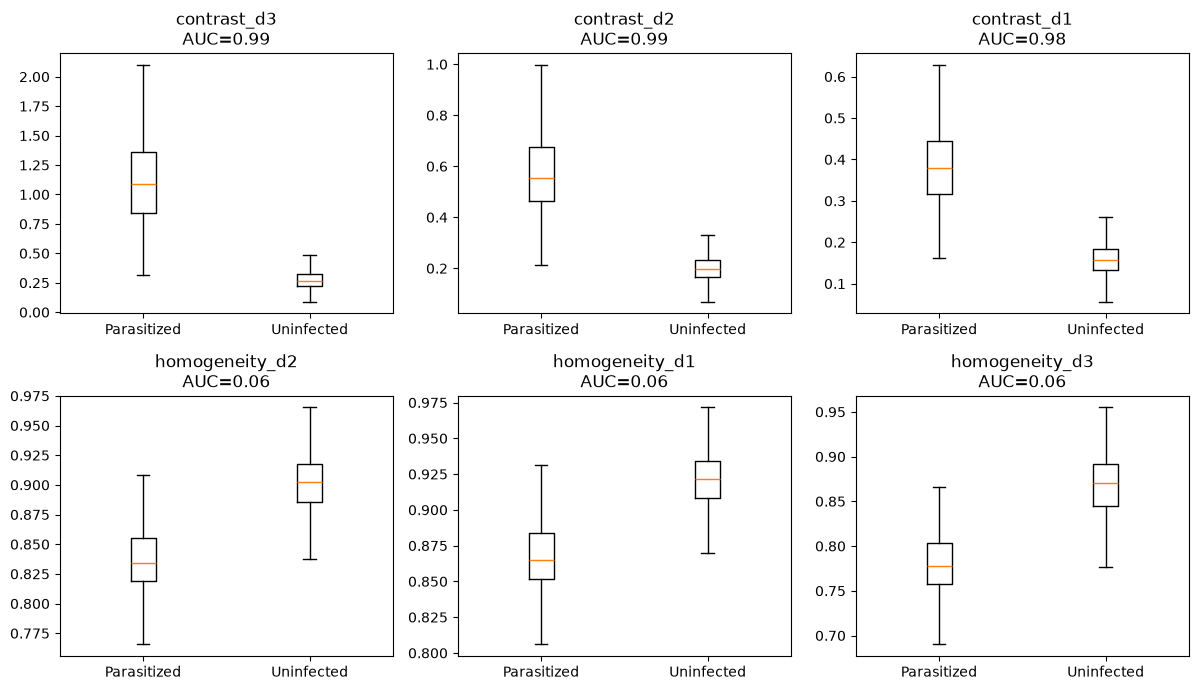

In [20]:
#Diagramas de caja y bigote
top = ranking["feature"].head(6).tolist() # los 6 mejores descriptores

fig, axs = plt.subplots(2, 3, figsize=(12, 7))
for ax, f in zip(axs.ravel(), top):
    datos = [train.loc[train.label == c, f].dropna() for c in CLASES]
    ax.boxplot(datos, tick_labels=CLASES, showfliers=False)
    ax.set_title(f"{f}\nAUC={ranking.set_index('feature').loc[f, 'auc']:.2f}")
plt.tight_layout()
plt.show()

In [21]:
def auc_pac(g, f):
    #AUC de un descriptor dentro de un solo paciente (NaN si hay muy pocas células)
    p = g.loc[g.label == "Parasitized", f]
    u = g.loc[g.label == "Uninfected", f]
    if len(p) < 5 or len(u) < 5:
        return np.nan
    return mannwhitneyu(p, u)[0] / (len(p) * len(u))
# Tabla con pacientes en las filas y descriptores en las columnas
por_pac = pd.DataFrame({f: train.groupby("patient_id").apply(lambda g: auc_pac(g, f))
                        for f in top})
display(por_pac.round(2))

# AUC del descriptor "tamaño": referencia para ver si la textura aporta algo más
print("AUC n_pixeles:", mannwhitneyu(
    train.loc[train.label == "Parasitized", "n_pixeles"],
    train.loc[train.label == "Uninfected", "n_pixeles"])[0]
    / ((train.label == "Parasitized").sum() * (train.label == "Uninfected").sum()))

,contrast_d3,contrast_d2,contrast_d1,homogeneity_d2,homogeneity_d1,homogeneity_d3
patient_id,,,,,,
208C67P28N_ThinF,1.00,0.99,0.99,0.18,0.17,0.19
209C68P29N_ThinF,0.98,0.98,0.98,0.09,0.08,0.13
211C70P31_ThinF,1.00,1.00,0.99,0.06,0.05,0.08
212C71P32_ThinF,1.00,1.00,1.00,0.06,0.06,0.04
263C115P76ThinF,0.90,0.88,0.84,0.20,0.23,0.18
282C134P95ThinF,NaN,NaN,NaN,NaN,NaN,NaN


AUC n_pixeles: 0.5182065422678854


Seleccionados: ['contrast_d3', 'correlation_d1', 'energy_d1']


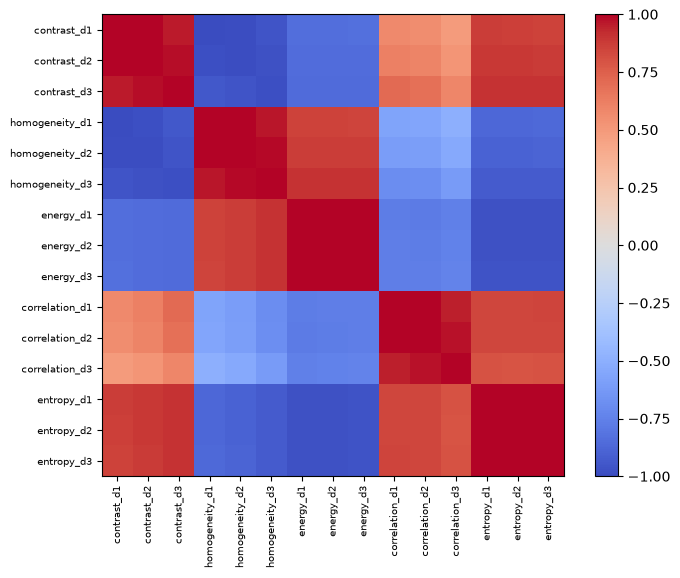

In [22]:
#calculamos la matriz de correlación de spearman para detectar
#descriptores redundantes (si estan muy correlacionados entre si, uno
# es función de la otra)
corr = train[feat_cols].corr(method="spearman")

seleccion = []
for f in ranking["feature"]: # de mejor a peor AUC
    if ranking.set_index("feature").loc[f, "separacion"] < 0.6:
        break                      # descarto lo que casi no separa
    # Lo agrego solo si no es casi copia de uno ya elegido (umbral de 0.9)
    if all(abs(corr.loc[f, s]) < 0.9 for s in seleccion):
        seleccion.append(f)

print("Seleccionados:", seleccion)

# Mapa de calor: bloques rojos/azules intensos = descriptores redundantes
plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(feat_cols)), feat_cols, rotation=90, fontsize=7)
plt.yticks(range(len(feat_cols)), feat_cols, fontsize=7)
plt.colorbar()
plt.show()

In [23]:
#Guardo rankng y selección
out = ROOT_PROY / "texture_eval" / "results"
ranking.to_csv(out / "b2_ranking_atributos.csv", index=False)
pd.Series(seleccion, name="feature").to_csv(out / "b2_atributos_seleccionados.csv", index=False)

In [24]:
#Probamos si funciona evaluar_imagen de seg_metrics en las GT y modificadas
from texture_eval.seg_metrics import evaluar_imagen
from skimage.morphology import dilation, disk


# Imagen de prueba
reg = cargar_subset("train")[0]
img = cargar_imagen(reg["patient_id"], reg["image_id"])
anot, _ = cargar_gt(reg["patient_id"], reg["image_id"])
gt = mapa_gt(img.shape, anot)

# 1) pred = GT  -> TP = N, FP = FN = 0, Dice = IoU = 1
r = evaluar_imagen(gt, gt); print({k: v for k, v in r.items() if k != "pares"})

# 2) pred con bordes dilatados -> IoU baja pero siguen siendo TP
pred = dilation(gt, disk(3))
r = evaluar_imagen(gt, pred); print({k: v for k, v in r.items() if k != "pares"})

# 3) pred con 20 células borradas -> FN = 20
pred = gt.copy()
for i in np.unique(gt)[1:21]: pred[pred == i] = 0
r = evaluar_imagen(gt, pred); print({k: v for k, v in r.items() if k != "pares"})

KeyboardInterrupt: 

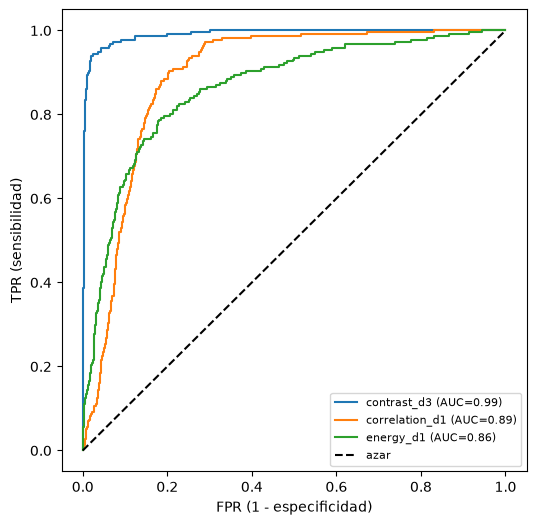

In [ ]:
#Calculamos y graficamos las curvas ROC para los features seleccionados
from sklearn.metrics import roc_curve

y = (train["label"] == "Parasitized").astype(int).values  # 1 = parasitada, 0 = no infectada
P, N = y.sum(), (1 - y).sum() # cantidad de cada clase
auc_de = ranking.set_index("feature")["auc"] # AUC de cada descriptor

def curva(f):
    # si el AUC < 0,5, la parasitada tiene valores MENORES: invierto el signo
    # para que "score alto = parasitada" y roc_curve funcione siempre igual
    sentido = 1 if auc_de[f] >= 0.5 else -1
    score = sentido * train[f].values
    fpr, tpr, thr = roc_curve(y, score)
    return sentido, fpr, tpr, thr

plt.figure(figsize=(6, 6))
for f in seleccion:
    _, fpr, tpr, _ = curva(f)
    plt.plot(fpr, tpr, label=f"{f} (AUC={max(auc_de[f], 1-auc_de[f]):.2f})")
plt.plot([0, 1], [0, 1], "k--", label="azar")
plt.xlabel("FPR (1 - especificidad)"); plt.ylabel("TPR (sensibilidad)")
plt.legend(fontsize=8); plt.show()

In [ ]:
def elegir_umbral(f):
    #Devuelve el umbral óptimo de un descriptor según Youden y según F1.
    sentido, fpr, tpr, thr = curva(f)

    # Youden: maximiza sensibilidad - (1 - especificidad)
    youden = tpr - fpr
    i_y = youden.argmax()

    # F1: pasa de tasas a conteos para calcular la precisión en cada umbral
    tp, fp = tpr * P, fpr * N
    prec = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) > 0)
    f1 = np.divide(2 * prec * tpr, prec + tpr, out=np.zeros_like(tpr), where=(prec + tpr) > 0)
    i_f = f1.argmax()

    filas = []
    for nombre, i in [("Youden", i_y), ("F1", i_f)]:
        filas.append({
            "feature": f, "criterio": nombre,
            "regla": f"{f} {'>=' if sentido == 1 else '<='} {sentido * thr[i]:.4f}",
            "umbral": sentido * thr[i], "sentido": sentido,
            "sensibilidad": tpr[i], "especificidad": 1 - fpr[i],
            "precision": prec[i], "F1": f1[i],
        })
    return filas

umbrales = pd.DataFrame([r for f in seleccion for r in elegir_umbral(f)])
umbrales.round(3)

,feature,criterio,regla,umbral,sentido,sensibilidad,especificidad,precision,F1
0,contrast_d3,Youden,contrast_d3 >= 0.5958,0.596,1,0.940,0.981,0.833,0.883
1,contrast_d3,F1,contrast_d3 >= 0.6984,0.698,1,0.894,0.990,0.898,0.896
2,correlation_d1,Youden,correlation_d1 >= 0.9437,0.944,1,0.903,0.797,0.311,0.463
3,correlation_d1,F1,correlation_d1 >= 0.9491,0.949,1,0.797,0.851,0.352,0.489
4,energy_d1,Youden,energy_d1 <= 0.4176,0.418,-1,0.788,0.821,0.309,0.444
5,energy_d1,F1,energy_d1 <= 0.3814,0.381,-1,0.627,0.911,0.418,0.502


In [ ]:
#Calcula valor del umbral según el criterio de Youden
def umbral_youden(df_, f, sentido):
    yy = (df_["label"] == "Parasitized").astype(int).values
    fpr, tpr, thr = roc_curve(yy, sentido * df_[f].values)
    return thr[(tpr - fpr).argmax()]

filas = []
for f in seleccion:
    sentido = 1 if auc_de[f] >= 0.5 else -1
    for pac in train["patient_id"].unique():
        fit, val = train[train.patient_id != pac], train[train.patient_id == pac]
        t = umbral_youden(fit, f, sentido)
        pred = (sentido * val[f].values >= t)
        real = (val["label"] == "Parasitized").values
        filas.append({"feature": f, "paciente_fuera": pac, "umbral": sentido * t,
                      "TP": (pred & real).sum(), "FP": (pred & ~real).sum(),
                      "FN": (~pred & real).sum(), "TN": (~pred & ~real).sum()})

loo = pd.DataFrame(filas)
display(loo.pivot(index="paciente_fuera", columns="feature", values="umbral").round(3))  # ¿es estable?

# Métricas acumuladas sumando los pacientes dejados afuera
res = loo.groupby("feature")[["TP", "FP", "FN", "TN"]].sum()
res["sensibilidad"] = res.TP / (res.TP + res.FN)
res["precision"] = res.TP / (res.TP + res.FP)
res["F1"] = 2 * res.precision * res.sensibilidad / (res.precision + res.sensibilidad)
res.round(3)

feature,contrast_d3,correlation_d1,energy_d1
paciente_fuera,,,
208C67P28N_ThinF,0.596,0.946,0.418
209C68P29N_ThinF,0.385,0.934,0.461
211C70P31_ThinF,0.596,0.934,0.422
212C71P32_ThinF,0.596,0.947,0.418
263C115P76ThinF,0.596,0.944,0.418
282C134P95ThinF,0.596,0.944,0.418


,TP,FP,FN,TN,sensibilidad,precision,F1
feature,,,,,,,
contrast_d3,204,179,13,1956,0.940,0.533,0.680
correlation_d1,199,492,18,1643,0.917,0.288,0.438
energy_d1,173,424,44,1711,0.797,0.290,0.425


In [ ]:
#Guardamos umbrales
umbrales.to_csv(ROOT_PROY / "texture_eval" / "results" / "b4_umbrales_textura.csv", index=False)